In [137]:
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split , GridSearchCV

In [6]:
insurance_data = pd.read_csv("Claimants.csv")

In [7]:
insurance_data.shape

(1340, 7)

In [8]:
insurance_data.describe()

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1340.000000,1340.000000,1328.000000,1299.000000,1292.000000,1151.000000,1340.000000
mean,11202.001493,0.488806,0.558735,0.907621,0.017028,28.414422,3.806307
std,9512.750796,0.500061,0.496725,0.289671,0.129425,20.304451,10.636903
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4177.000000,0.000000,0.000000,1.000000,0.000000,9.000000,0.400000
50%,8756.500000,0.000000,1.000000,1.000000,0.000000,30.000000,1.069500
75%,15702.500000,1.000000,1.000000,1.000000,0.000000,43.000000,3.781500
max,34153.000000,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


In [9]:
insurance_data.isna().su

CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

In [ ]:
insurance_data.drop_duplicates(inplace=True)

In [13]:
insurance_data[insurance_data.duplicated()]

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS


In [14]:
insurance_data.duplicated().sum()

np.int64(0)

In [15]:
insurance_data.dropna(inplace=True)

In [18]:
insurance_data.isna().sum()

CASENUM     0
ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

In [79]:
insurance_data.shape

(1096, 7)

In [23]:
y= insurance_data.iloc[:,1]
print(y)

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64


In [80]:
insurance_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1334,34104,1,1.0,1.0,0.0,16.0,0.060
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


In [85]:
X = insurance_data.drop(insurance_data.columns[[0,1]], axis=1)
X

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1334,1.0,1.0,0.0,16.0,0.060
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177


In [86]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=34)

In [41]:
X_train, X_test, y_train, y_test 

(     CASENUM  CLMSEX  CLMINSUR  SEATBELT  CLMAGE    LOSS
 478     1110     0.0       1.0       1.0    10.0   1.318
 387     9660     1.0       1.0       0.0    55.0   0.604
 47        78     0.0       1.0       0.0     1.0   0.000
 220     5504     1.0       1.0       1.0     7.0   0.983
 152     3605     1.0       1.0       0.0     6.0   0.075
 ..       ...     ...       ...       ...     ...     ...
 731     8814     0.0       1.0       0.0    30.0   4.014
 817    10060     0.0       1.0       0.0    48.0   0.390
 557     4375     0.0       1.0       0.0    30.0   0.565
 386     9653     1.0       1.0       0.0    35.0   0.860
 599     5519     1.0       1.0       0.0    37.0  63.361
 
 [876 rows x 6 columns],
       CASENUM  CLMSEX  CLMINSUR  SEATBELT  CLMAGE   LOSS
 627      6445     1.0       1.0       0.0    40.0  6.337
 1125    18941     1.0       1.0       0.0    37.0  4.609
 1124    18887     1.0       1.0       0.0    46.0  0.730
 1025    16338     1.0       1.0       0.0   

In [139]:
# dt_model = DecisionTreeClassifier(criterion='entropy',max_depth=7)
# dt_model

# dt_model = DecisionTreeClassifier(criterion='gini',max_depth=7)
# dt_model

GridSearchCV(estimator=dt_model,param_grid={"max_depth":  [5,6,7,8,9] , "criterion": ['gini','entropy']})

GridSearchCV(estimator=DecisionTreeClassifier(max_depth=7),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [5, 6, 7, 8, 9]})

In [140]:
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=7)

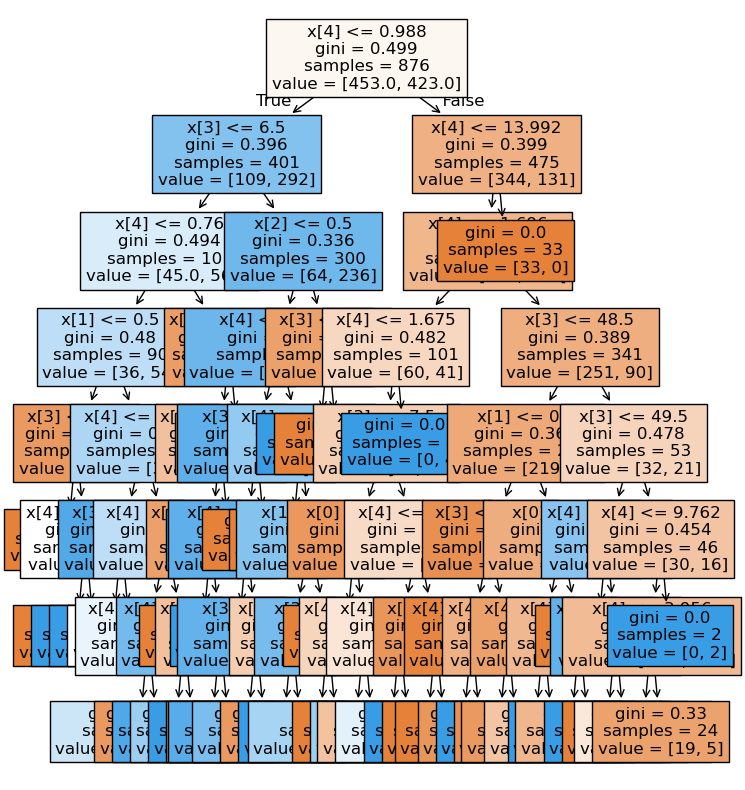

In [141]:
plt.figure( figsize = (8, 10),)
plot_tree(decision_tree = dt_model,fontsize=12,filled=True)
plt.show()

## Model Testing on Training data

In [142]:
y_pred_train = dt_model.predict(X_train)

In [143]:
y_pred_train

array([0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0,
       1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1,

## Model Testing on Testing data

In [144]:
y_pred_test= dt_model.predict(X_test)

In [103]:
y_pred_test

array([0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1,
       1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1,
       0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1,
       0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0])

In [145]:
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix,roc_curve, roc_auc_score

In [146]:
print (classification_report(y_train, y_pred_train))

              precision    recall  f1-score   support

           0       0.79      0.79      0.79       453
           1       0.78      0.77      0.77       423

    accuracy                           0.78       876
   macro avg       0.78      0.78      0.78       876
weighted avg       0.78      0.78      0.78       876



In [147]:
print (accuracy_score(y_train, y_pred_train))

0.7831050228310502


In [148]:
print (confusion_matrix(y_train, y_pred_train))

[[359  94]
 [ 96 327]]


## ROC Curve --> Reveiver Operating Characteristic

In [109]:
roc_curve(y_train, y_pred_train)

(array([0.        , 0.20750552, 1.        ]),
 array([0.        , 0.77304965, 1.        ]),
 array([inf,  1.,  0.]))

In [112]:
fpr, tpr, threshsolds = roc_curve(y_train, dt_model.predict_proba(X_train)[:,1])

In [113]:
fpr, tpr, threshsolds

(array([0.        , 0.        , 0.00662252, 0.00883002, 0.04415011,
        0.0816777 , 0.09271523, 0.12362031, 0.16777042, 0.20750552,
        0.20971302, 0.23399558, 0.26269316, 0.31788079, 0.53421634,
        0.57615894, 0.76379691, 0.77704194, 0.79470199, 1.        ]),
 array([0.        , 0.12056738, 0.1891253 , 0.21040189, 0.45626478,
        0.57683215, 0.60047281, 0.65957447, 0.72340426, 0.77304965,
        0.77541371, 0.79669031, 0.81323877, 0.84397163, 0.94326241,
        0.95508274, 0.99527187, 0.99763593, 1.        , 1.        ]),
 array([       inf, 1.        , 0.90625   , 0.9       , 0.86666667,
        0.75      , 0.66666667, 0.64102564, 0.57446809, 0.53846154,
        0.5       , 0.45      , 0.35      , 0.34210526, 0.3       ,
        0.20833333, 0.16666667, 0.14285714, 0.11111111, 0.        ]))

In [127]:
auc = roc_auc_score(y_train, y_pred_train)
auc

np.float64(0.7827720633131371)

Text(0, 0.5, 'TPR')

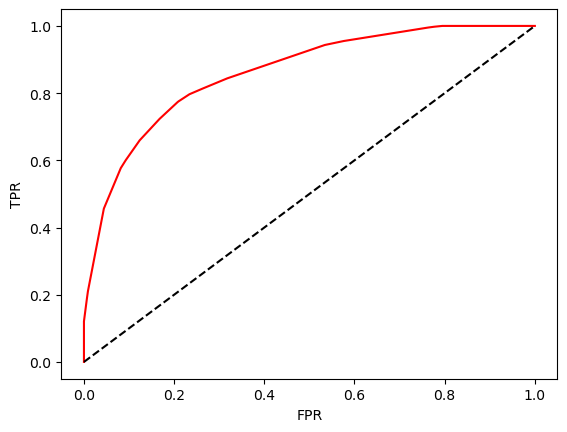

In [132]:
plt.plot(fpr, tpr, color='red', label='logit model (area  = %0.2f)'%auc)
plt.plot([0,1],[0,1],'k--')
plt.xlabel("FPR")
plt.ylabel("TPR")

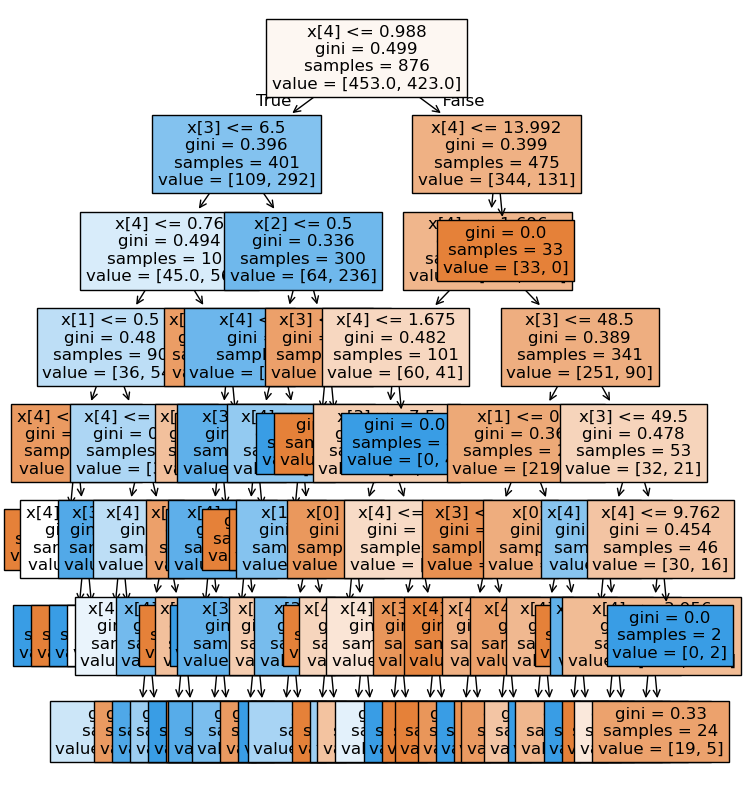

In [136]:
from matplotlib import pyplot as plt
plt.figure( figsize = (8, 10),)
plot_tree(decision_tree = dt_model,fontsize=12,filled=True)
plt.show()